# Spotify Song Popularity — Notebook 2: Lyrics Features

IS 507 Midterm Project (version 5). This notebook builds the lyrics features and TF-IDF representation, describes their association with popularity, and evaluates the baselines on the test set.

## Notebook Outline

| Section | Content | Main outputs | Report reference |
|---|---|---|---|
| 1.1–1.2 | Setup and loading the lyrics dataset from Notebook 1 (171,096 songs) with sanity checks | `df` | Table 2 |
| 1.3 | Verification of the stratified split (proportions, era composition, popularity) | `L00_split_overview.png` | Section 6.2 |
| 2.0 | Removal of residual section tags (`Chorus:`, `(x2)`, …) | `L00b_residual_tags.png` | Section 4.1 |
| 2.1 | Ten lyrics features: length, repetition, sentiment | Feature summary table | Section 4.1 |
| 2.2 | Train / validation / test sets; median imputation for songs with fewer than four lines | `L00c_line_count_check.png` | Section 6.2 |
| 2.3 | Data-driven choice of TF-IDF parameters | `L01_tfidf_parameter_choice.png` | Sections 4.1, 4.3 |
| 2.4 | TF-IDF matrix (20,000 terms), fit on the training set only | `Xt_tr`, `Xt_va`, `Xt_te` | Sections 4.3, 6.2 |
| 3.1 | Distributions of popularity and the lyrics features | `L02_distributions.png` | Sections 4.3, 5.1 |
| 3.2 | Correlations among the lyrics features | `L03_feature_intercorrelation.png` | Section 6.1 |
| 3.3 | Spearman correlation with popularity | `L04_spearman_by_dimension.png` (Figure 3, left) | Section 5.1 |


All figures are saved to `figures/lyrics/` at 200 dpi. Run the cells in order.

---
# Part 1 — Data Loading

## 1.1 Setup

This section loads the required packages and fixes the random seed.

| Package | Purpose |
|---|---|
| `pandas`, `numpy` | Data handling and numerical computation |
| `matplotlib`, `seaborn` | Visualization |
| `scipy` | Spearman correlation |
| `scikit-learn` | Term counting, TF-IDF, evaluation metrics |
| `nltk` | VADER sentiment lexicon |
| `zlib` | Compression (measure of lyrical repetition) |

A fixed random seed makes sampling reproducible. Only `FutureWarning` is suppressed; all other warnings are shown, because suppressing all warnings previously hid an sklearn warning about inconsistent stop words and tokenization.

In [3]:
import os
import re
import time
import zlib
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import nltk
nltk.download("vader_lexicon", quiet=True)
from nltk.sentiment.vader import SentimentIntensityAnalyzer

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

SPLIT_ORDER = ["train", "val", "test"]
SPLIT_COLORS = {"train": "#4C72B0", "val": "#DD8452", "test": "#C44E52"}
TIER_BINS = [0, 20, 40, 60, 80, 100]
TIER_LABELS = ["0-20", "20-40", "40-60", "60-80", "80-100"]
ERA_BINS = [2009, 2013, 2017, 2021, 2026]
ERA_LABELS = ["2009-2012", "2013-2016", "2017-2020", "2021-2025"]
ERA_COLORS = dict(zip(ERA_LABELS, sns.color_palette("viridis", len(ERA_LABELS))))
print("Packages loaded")

Packages loaded


## 1.2 Data Loading

The clean dataset produced by Notebook 1 is loaded from Google Drive. The parquet file is preferred because it preserves data types (e.g., `id` as text) and line breaks and loads faster; the CSV file is used only if the parquet file is unavailable, with `id` read as text. The first cell mounts Google Drive (Colab only); the second sets the paths and falls back to the working directory outside Colab.

**Checks after loading** (execution stops if any check fails)
1. All required columns are present (including `first_year` and `main_artist`); if the `era` column is absent, it is computed with the same rule as in Notebook 1.
2. `id` is unique (one row per song).
3. Every song has a valid `split` label.
4. `popularity` has no missing values.

In [4]:
# [COLAB_ONLY] Run this cell in Colab only
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
if os.path.exists("/content/drive/MyDrive"):
    PROJECT_DIR = "/content/drive/MyDrive/IS507_Spotify_Project"
else:
    PROJECT_DIR = os.path.abspath("IS507_Spotify_Project")
DATA_DIR = f"{PROJECT_DIR}/data"
FIG_DIR = f"{PROJECT_DIR}/figures/lyrics"
RESULT_DIR = f"{PROJECT_DIR}/results"
for d in [DATA_DIR, FIG_DIR, RESULT_DIR]:
    os.makedirs(d, exist_ok=True)

PARQUET_PATH = f"{DATA_DIR}/songs_clean.parquet"
CSV_PATH = f"{DATA_DIR}/songs_clean.csv"

t0 = time.time()
if os.path.exists(PARQUET_PATH):
    df = pd.read_parquet(PARQUET_PATH)
    source = "parquet"
else:
    df = pd.read_csv(CSV_PATH, dtype={"id": str}, low_memory=False)
    source = "csv"
df["id"] = df["id"].astype(str)
print(f"Loaded ({source}): {df.shape[0]:,} songs × {df.shape[1]} columns ({time.time() - t0:.1f} s)")

REQUIRED = ["id", "main_artist", "year", "first_year", "genre", "popularity", "split", "lyrics_clean"]
missing_cols = [c for c in REQUIRED if c not in df.columns]
assert not missing_cols, f"Missing columns: {missing_cols}; check that the file is the Notebook 1 output"
assert df["id"].is_unique, "Duplicate ids!"
assert df["split"].isin(SPLIT_ORDER).all(), "Some songs have an invalid split label!"
assert df["popularity"].notna().all(), "Missing popularity values!"
print("All sanity checks passed")

df["lyrics_clean"] = df["lyrics_clean"].fillna("").astype(str)
df["genre"] = df["genre"].fillna("Unknown").astype(str)
df["main_artist"] = df["main_artist"].fillna("unknown").astype(str)
df["first_year"] = df["first_year"].astype(int)
df["year"] = df["year"].astype(int)
if "era" not in df.columns:
    df["era"] = pd.cut(df["first_year"], bins=ERA_BINS, labels=ERA_LABELS, right=False).astype(str)
df["era"] = df["era"].astype(str)
assert df["era"].isin(ERA_LABELS).all(), "Some songs have an era outside ERA_LABELS; check that the year range is 2009–2025"

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

df.drop(columns=["lyrics_clean"]).head(3)

Loaded (parquet): 171,096 songs × 34 columns (8.7 s)
All sanity checks passed


,id,name,artists,main_artist,album_name,year,first_year,genre,popularity,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,avg_artist_popularity,total_artist_followers,era,has_lyrics,lyrics_n_words,en_stopword_ratio,non_ascii_ratio,lyrics_group_id,split,split_random,split_artist_group,split_temporal,artist_cluster,artist_seen_in_train,lyrics_model_text
0,0005VnpISGYLSGrXg9TEJS,Space Loneliness,"[""SadDoLLs""]",saddolls,About Darkness,2009,2009,Rock,1,0.2970,0.2760,-10.9370,0.0410,0.4650,0.7630,0.1070,0.0332,125.1590,25.0000,5514,2009-2012,1,60,0.4394,0.0000,ef97b8b48a9f90e13559f4913a039e78da0ed84dd1d5ef...,train,train,test,train,12174,1,I Feel lost... The stars are now my family...\...
1,000cAxMxUfuDlvPYIVrrZ4,Mind Control,"[""Tantric""]",tantric,Mind Control,2009,2009,Rock,27,0.4740,0.9660,-2.9570,0.0931,0.0001,0.0000,0.3740,0.6020,156.9930,46.0000,230680,2009-2012,1,198,0.4478,0.0000,71638a94a6b5c82cc8cad8fd5bbfcbe4ba693265129183...,val,val,train,train,7226,1,"Oh, the line of mass hysteria\nHas turned into..."
2,003KqHsoqMVwh3BnGNvNBs,Hard To Be Vain,"[""Vains Of Jenna""]",vains of jenna,Lit Up / Let Down,2009,2009,Rock,14,0.3930,0.7210,-9.4360,0.0438,0.0000,0.5430,0.0662,0.4170,131.9330,35.0000,19978,2009-2012,1,369,0.5509,0.0000,0b0b1e40a51f5b9b3b969741cc5d6775f333760bdbc9af...,train,train,train,train,13528,1,Sexy sugar on the subway train\nIt's all about...


## 1.3 Split Check: Random Stratified Split

Notebook 1 split the data **randomly** into training (70%), validation (15%), and test (15%) sets, **stratified** by era × genre. Stratified sampling draws the same proportion from each stratum (e.g., "2013–2016 Rock"), so that the era and genre composition of each split matches that of the full data. This section verifies the split numerically and graphically.

### Automatic checks

| Check | Criterion | Rationale |
|---|---|---|
| (1) Split proportions | Within 2 percentage points of 70 / 15 / 15 | Duplicate-lyrics groups are assigned as a whole, so proportions may deviate slightly |
| (2) Era composition | Share of each era within 2 percentage points of the training set | Evidence of successful stratification |
| (3) Mean popularity | Differences below 1 point | No popularity shift between splits |

If (1) or (2) fails, the data are treated as a temporal split and a warning is printed (this occurs when `SPLIT_METHOD = "temporal"` is used in Notebook 1 as a robustness run). The notebook still runs, but the interpretation of the baseline R² in 4.1 must be adapted.

### Figures

| Panel | Content | Expected pattern |
|---|---|---|
| (a) Era composition by split | Success of stratification | Nearly identical proportions |
| (b) Popularity by split | Distribution of the target | Boxes and means at nearly the same level |
| (c) `first_year` distribution by split | Coverage of 2009–2025 | Overlapping lines |

The split from Notebook 1 is used unchanged (research-design principle: the question concerns the predictive power of song content; era differences are analyzed in SQ5). The number of songs, proportions, and mean popularity of each split are reported in the summary table.

(1) Split shares: train 70.0%, val 15.0%, test 15.0% (max deviation from 70/15/15: 0.00 pp)
(2) Max era-composition gap: 0.03 pp
(3) Mean popularity: train 25.98, val 26.02, test 26.00 (test − train = +0.03 points)
Split check passed: random stratified split; shares, era composition, and popularity are consistent across splits


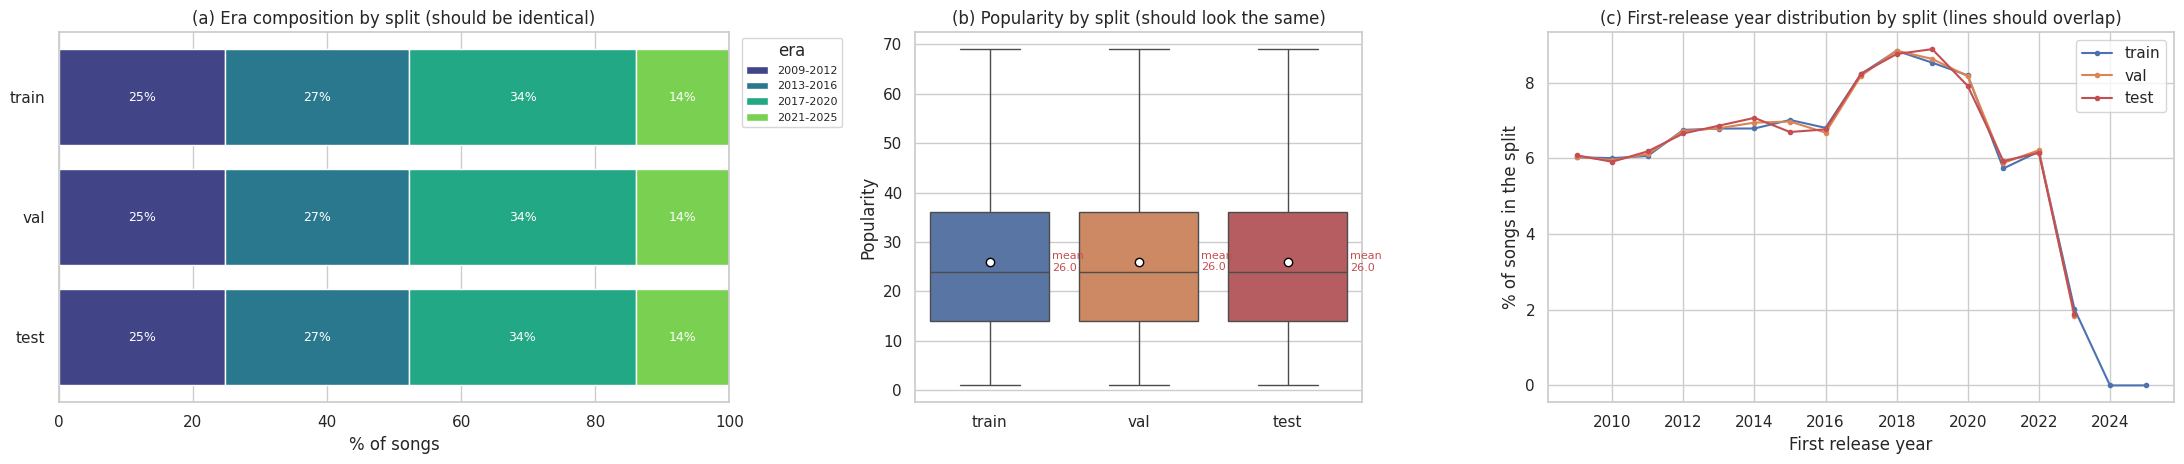

,n_songs,first_year_min,first_year_max,pop_mean,pop_median,share
split,,,,,,
train,119763,2009,2025,25.9782,24.0000,0.7000
val,25668,2009,2023,26.0225,24.0000,0.1500
test,25665,2009,2023,26.0048,24.0000,0.1500


In [6]:
target_share = pd.Series({"train": 0.70, "val": 0.15, "test": 0.15})
share = df["split"].value_counts(normalize=True).reindex(SPLIT_ORDER)
era_mix = pd.crosstab(df["split"], df["era"], normalize="index").reindex(SPLIT_ORDER)[ERA_LABELS] * 100
share_gap_pp = (share - target_share).abs().max() * 100
era_gap_pp = (era_mix - era_mix.loc["train"]).abs().max().max()
SPLIT_MODE = "random" if (share_gap_pp < 2 and era_gap_pp < 2) else "temporal"
pop_means = df.groupby("split")["popularity"].mean().reindex(SPLIT_ORDER)

print(f"(1) Split shares: {', '.join(f'{s} {share[s]:.1%}' for s in SPLIT_ORDER)} (max deviation from 70/15/15: {share_gap_pp:.2f} pp)")
print(f"(2) Max era-composition gap: {era_gap_pp:.2f} pp")
print(f"(3) Mean popularity: {', '.join(f'{s} {pop_means[s]:.2f}' for s in SPLIT_ORDER)} (test − train = {pop_means['test'] - pop_means['train']:+.2f} points)")
if SPLIT_MODE == "random":
    print("Split check passed: random stratified split; shares, era composition, and popularity are consistent across splits")
else:
    print("Warning: the data appear to use a temporal split (SPLIT_METHOD = 'temporal'). The notebook runs, but the interpretation in 4.1 and 4.8 must be adapted.")

split_summary = (
    df.groupby("split")
      .agg(n_songs=("id", "size"),
           first_year_min=("first_year", "min"),
           first_year_max=("first_year", "max"),
           pop_mean=("popularity", "mean"),
           pop_median=("popularity", "median"))
      .reindex(SPLIT_ORDER)
)
split_summary["share"] = (split_summary["n_songs"] / len(df)).round(3)

fig, axes = plt.subplots(1, 3, figsize=(22, 4.8), gridspec_kw={"width_ratios": [1.5, 1, 1.4]})
left = np.zeros(len(era_mix))
for e in ERA_LABELS:
    axes[0].barh(era_mix.index, era_mix[e], left=left, color=ERA_COLORS[e], label=e)
    for i, v in enumerate(era_mix[e]):
        if v >= 6:
            axes[0].text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += era_mix[e].values
axes[0].invert_yaxis()
axes[0].set(xlim=(0, 100), xlabel="% of songs", title="(a) Era composition by split (should be identical)")
axes[0].legend(title="era", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)

sns.boxplot(data=df, x="split", y="popularity", order=SPLIT_ORDER, palette=SPLIT_COLORS, showfliers=False, showmeans=True,
            meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black"}, ax=axes[1])
for i, s_ in enumerate(SPLIT_ORDER):
    axes[1].text(i + 0.42, pop_means[s_], f"mean\n{pop_means[s_]:.1f}", ha="left", va="center", fontsize=8, color="#C44E52")
axes[1].set(title="(b) Popularity by split (should look the same)", xlabel="", ylabel="Popularity")

for s_ in SPLIT_ORDER:
    yr_share = df.loc[df["split"] == s_, "first_year"].value_counts(normalize=True).sort_index() * 100
    axes[2].plot(yr_share.index, yr_share.values, marker="o", ms=3, color=SPLIT_COLORS[s_], label=s_)
axes[2].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[2].set(title="(c) First-release year distribution by split (lines should overlap)", xlabel="First release year", ylabel="% of songs in the split")
axes[2].legend()
savefig("L00_split_overview")

split_summary

---
# Part 2 — Lyrics Feature Engineering

## 2.0 Residual Section Tags

In an earlier version, the most negative TF-IDF terms of the Ridge model were `chorus`, `instrumental`, and `solo`. These are annotations added by lyrics websites, not sung words. Notebook 1 removed bracketed tags (`[Chorus]`), but other forms remained:

| Form | Examples |
|---|---|
| Whole line containing only a tag | `Chorus:`, `Verse 2`, `Guitar Solo`, `Instrumental` |
| Tags in parentheses / braces | `(Chorus)`, `{Repeat Chorus}` |
| Repeat markers | `(x2)`, `2x` |

Lyrics of less popular songs tend to come from less carefully edited sources and therefore contain more annotations. A model would learn that the presence of `chorus` predicts lower popularity, which reflects **lyric-source quality** rather than content and would bias the keyword conclusions of SQ2.

The three forms are identified with regular expressions and removed; the result is stored in `lyrics_model` (`lyrics_clean` is kept for comparison).

Only lines consisting entirely of a tag are removed; the word "chorus" within sung lyrics is retained, which minimizes the risk of deleting genuine lyrics. The operation is applied to each song independently and uses no information from other songs, so it can be performed before splitting without leakage.

**Figure**: the 15 most common removed tag lines (left) and the share of songs affected by each form (right).

Residual tag cleaning completed (68.1 s)


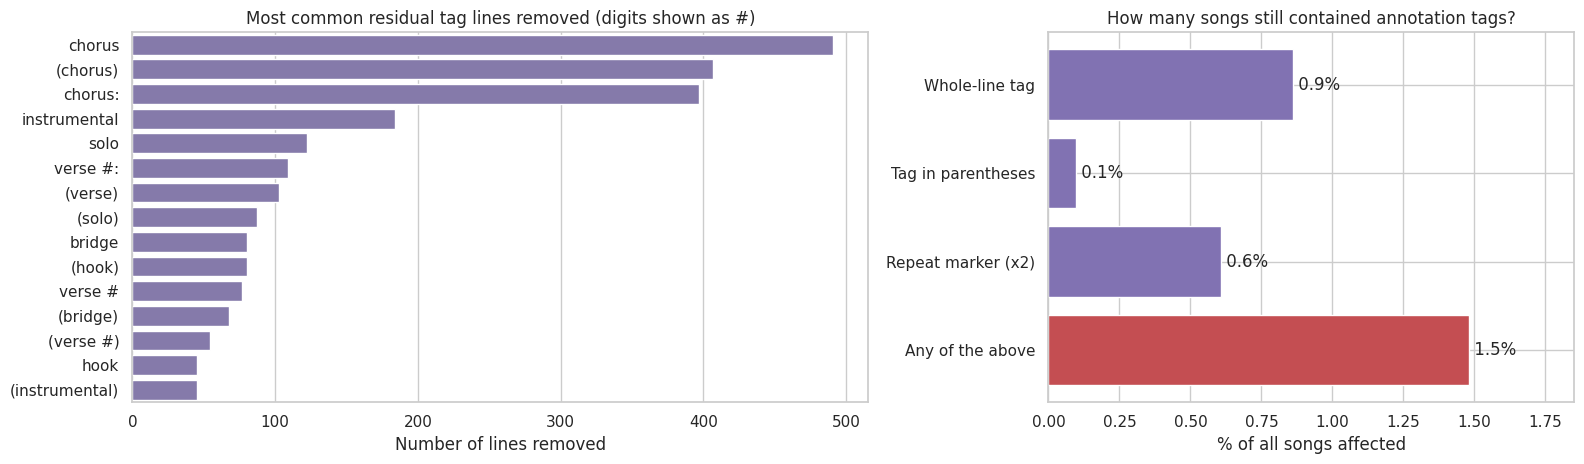

Songs with tags: 1.5%; mean words removed per song: 0.04
Songs with fewer than 20 words after cleaning: 1 (retained to keep row alignment with the audio dataset)

--- Example: removed lines ---
 ['[chorus}', '[chorus}', '[chorus}']


In [7]:
TAG_WORDS = (r"(?:pre[- ]?chorus|post[- ]?chorus|chorus|refrain|hook|verse|bridge|intro|outro|interlude|"
             r"breakdown|instrumental|(?:guitar |piano |sax |drum )?solo)")
TAG_LINE_RE = re.compile(
    rf"^\s*[\(\[\{{]?\s*(?:repeat\s+)?{TAG_WORDS}(?:\s*\d+)?\s*(?:[:\-–]\s*[^\n]{{0,30}})?"
    rf"\s*(?:\(?\s*(?:x\s*\d+|\d+\s*x)\s*\)?)?\s*[\)\]\}}]?\s*:?\s*$", re.IGNORECASE)
PAREN_TAG_RE = re.compile(rf"[\(\{{]\s*(?:repeat\s+)?{TAG_WORDS}[^\)\}}\n]{{0,30}}[\)\}}]", re.IGNORECASE)
REPEAT_RE = re.compile(r"[\(\[]\s*(?:x\s?\d{1,2}|\d{1,2}\s?x)\s*[\)\]]|\b(?:x\d{1,2}|\d{1,2}x)\b", re.IGNORECASE)

def remove_residual_tags(text):
    kept, removed, n_paren, n_repeat = [], [], 0, 0
    for line in text.split("\n"):
        if TAG_LINE_RE.match(line):
            removed.append(line.strip().lower())
            continue
        line, k1 = PAREN_TAG_RE.subn(" ", line)
        line, k2 = REPEAT_RE.subn(" ", line)
        n_paren, n_repeat = n_paren + k1, n_repeat + k2
        line = re.sub(r"[ \t]+", " ", line).strip()
        if line:
            kept.append(line)
    return "\n".join(kept), removed, n_paren, n_repeat

t0 = time.time()
out = [remove_residual_tags(t) for t in df["lyrics_clean"].values]
df["lyrics_model"] = [o[0] for o in out]
tag_lines = [o[1] for o in out]
has_line_tag = np.array([len(r) > 0 for r in tag_lines])
has_paren_tag = np.array([o[2] > 0 for o in out])
has_repeat = np.array([o[3] > 0 for o in out])
print(f"Residual tag cleaning completed ({time.time() - t0:.1f} s)")

common_tags = Counter(re.sub(r"\d+", "#", t) for r in tag_lines for t in r).most_common(15)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
if common_tags:
    tags_df = pd.DataFrame(common_tags, columns=["tag", "count"])
    sns.barplot(data=tags_df, y="tag", x="count", color="#8172B2", ax=axes[0])
axes[0].set_title("Most common residual tag lines removed (digits shown as #)")
axes[0].set_xlabel("Number of lines removed")
axes[0].set_ylabel("")
shares = pd.Series({"Whole-line tag": has_line_tag.mean() * 100,
                    "Tag in parentheses": has_paren_tag.mean() * 100,
                    "Repeat marker (x2)": has_repeat.mean() * 100,
                    "Any of the above": (has_line_tag | has_paren_tag | has_repeat).mean() * 100})
axes[1].barh(shares.index, shares.values, color=["#8172B2"] * 3 + ["#C44E52"])
for i, v in enumerate(shares.values):
    axes[1].text(v, i, f" {v:.1f}%", va="center")
axes[1].invert_yaxis()
axes[1].set_xlim(0, max(shares.max() * 1.25, 1))
axes[1].set_xlabel("% of all songs affected")
axes[1].set_title("How many songs still contained annotation tags?")
savefig("L00b_residual_tags")

words_before = df["lyrics_clean"].str.lower().str.count(r"[a-z']+")
words_after = df["lyrics_model"].str.lower().str.count(r"[a-z']+")
print(f"Songs with tags: {(has_line_tag | has_paren_tag | has_repeat).mean():.1%}; mean words removed per song: {(words_before - words_after).mean():.2f}")
print(f"Songs with fewer than 20 words after cleaning: {(words_after < 20).sum():,} (retained to keep row alignment with the audio dataset)")
ex_idx = int(np.argmax(has_line_tag)) if has_line_tag.any() else 0
print("\n--- Example: removed lines ---\n", tag_lines[ex_idx][:5])

## 2.1 Ten Simple Features in Three Dimensions

Ten numeric features are computed from each song's lyrics (`lyrics_model`), grouped into the three dimensions of SQ2: **length, repetition, and sentiment**. The fourth dimension, **keywords**, is represented by TF-IDF (2.3–2.4).

### Dimension 1: Length

| Feature | Definition |
|---|---|
| `word_count` | Number of English words |
| `line_count` | Number of non-empty lines |
| `words_per_line` | Words divided by lines |

### Dimension 2: Repetition

| Feature | Definition | Higher values indicate |
|---|---|---|
| `unique_word_ratio` | Distinct words ÷ total words | **Less** repetition (more varied vocabulary) |
| `line_repetition_rate` | 1 − distinct lines ÷ total lines | More repetition |
| `top_line_share` | Occurrences of the most frequent line ÷ total lines | More repetition (typically the hook) |
| `compressibility` | 1 − compressed size ÷ original size | More repetition |

For example, a song with 40 lines of which 28 are distinct has `line_repetition_rate` = 1 − 28/40 = 0.30; if its most frequent line occurs 6 times, `top_line_share` = 6/40 = 0.15.

Compression algorithms such as zlib (LZ77) replace previously seen segments with back-references, so more repetitive lyrics compress more. Compressibility captures repeated words, phrases, and entire lines and is used in music information retrieval as a measure of lyrical repetition.

`unique_word_ratio` has the opposite orientation to the other three repetition features (higher = less repetitive), which must be taken into account when interpreting correlations.

### Dimension 3: Sentiment

| Feature | Definition |
|---|---|
| `sentiment_mean` | Mean VADER valence of lexicon words in the lyrics, rescaled to −1 to 1 |
| `pos_word_ratio` | Positive words ÷ total words |
| `neg_word_ratio` | Negative words ÷ total words |

VADER is a lexicon in which each word has a human-annotated valence between −4 and 4. The mean valence of the lexicon words in a song is divided by 4. Positive and negative word ratios are computed separately because songs with many positive and many negative words can have a mean near 0 despite strong emotional content.

**Simplified versus full VADER**

| Option | Advantages | Disadvantages |
|---|---|---|
| Full VADER (sentence-level) | Handles negation and intensifiers | Slow for about 170,000 songs; scores for long texts concentrate near ±1 and lose discrimination |
| **Simplified (lexicon average)** | Fast, interpretable, more dispersed scores | Negation is not handled ("not happy" counts as positive); listed as a limitation |

All features are computed from each song independently and use no information from other songs, so they can be computed before splitting without leakage. The summary table reports the range of each feature and confirms that there are no missing values.

In [8]:
VADER_LEX = SentimentIntensityAnalyzer().lexicon
TOKEN_RE = re.compile(r"[a-z']+")

FEATURE_GROUPS = {
    "Length": ["word_count", "line_count", "words_per_line"],
    "Repetition": ["unique_word_ratio", "line_repetition_rate", "top_line_share", "compressibility"],
    "Sentiment": ["sentiment_mean", "pos_word_ratio", "neg_word_ratio"],
}
LYRIC_FEATURES = [f for fs in FEATURE_GROUPS.values() for f in fs]
FEATURE_TO_GROUP = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
GROUP_COLORS = {"Length": "#4C72B0", "Repetition": "#DD8452", "Sentiment": "#55A868"}

def lyric_features(text):
    lines = [ln.strip().lower() for ln in text.split("\n") if ln.strip()]
    tokens = TOKEN_RE.findall(text.lower())
    n = len(tokens)
    n_lines = len(lines)
    uniq = len(set(tokens))
    top_line = max(Counter(lines).values()) if n_lines else 0
    raw = "\n".join(lines).encode("utf-8")
    comp = 1 - len(zlib.compress(raw)) / len(raw) if raw else 0.0
    scores = [VADER_LEX[t] for t in tokens if t in VADER_LEX]
    n_pos = sum(1 for s in scores if s > 0)
    n_neg = sum(1 for s in scores if s < 0)
    return (
        n,
        n_lines,
        n / n_lines if n_lines else 0.0,
        uniq / n if n else 0.0,
        1 - len(set(lines)) / n_lines if n_lines else 0.0,
        top_line / n_lines if n_lines else 0.0,
        comp,
        (sum(scores) / len(scores)) / 4 if scores else 0.0,
        n_pos / n if n else 0.0,
        n_neg / n if n else 0.0,
    )

t0 = time.time()
feat_rows = [lyric_features(t) for t in df["lyrics_model"].values]
df[LYRIC_FEATURES] = pd.DataFrame(feat_rows, index=df.index, columns=LYRIC_FEATURES).astype(float)
print(f"Lyrics features computed: {len(df):,} songs ({time.time() - t0:.1f} s)")
assert df[LYRIC_FEATURES].isna().sum().sum() == 0, "Missing values in lyrics features!"

df[LYRIC_FEATURES].describe().T

Lyrics features computed: 171,096 songs (38.2 s)


,count,mean,std,min,25%,50%,75%,max
word_count,"171,096.0000",261.5449,155.1771,13.0000,158.0000,231.0000,323.0000,"5,341.0000"
line_count,"171,096.0000",40.2323,20.9328,1.0000,26.0000,37.0000,50.0000,798.0000
words_per_line,"171,096.0000",6.7062,6.1074,1.0417,5.3199,6.3333,7.5429,674.0000
unique_word_ratio,"171,096.0000",0.4113,0.1462,0.0074,0.3118,0.3935,0.4979,1.0000
line_repetition_rate,"171,096.0000",0.3079,0.1936,0.0000,0.1633,0.3095,0.4375,0.9897
top_line_share,"171,096.0000",0.1360,0.0984,0.0050,0.0741,0.1111,0.1667,1.0000
compressibility,"171,096.0000",0.6289,0.1058,0.0581,0.5612,0.6388,0.7005,0.9810
sentiment_mean,"171,096.0000",0.0396,0.2396,-0.9250,-0.1250,0.0313,0.2020,0.8250
pos_word_ratio,"171,096.0000",0.0548,0.0388,0.0000,0.0294,0.0472,0.0709,0.5625
neg_word_ratio,"171,096.0000",0.0481,0.0383,0.0000,0.0215,0.0404,0.0656,0.5806


## 2.2 Train / Validation / Test Sets and Songs with Few Lines

1. The data are divided according to the `split` column, and the target values (popularity) are extracted for each set.
2. Songs with very few lines are handled.

The sets are separated at this point because the subsequent steps (TF-IDF, standardization, imputation) learn from data and must be fit on the training set only.

### Songs with very few lines

Notebook 1 corrected line breaks stored as literal text (99.9% of songs have real line breaks), but a small number of songs have only 1–3 lines, either because the lyrics lack line breaks or because they are very short. For these songs the **line-based features** (`line_count`, `words_per_line`, `line_repetition_rate`, `top_line_share`) are not meaningful: with a single line, the line repetition rate is necessarily 0 and words per line equals the total word count.

| Option | Advantages | Disadvantages |
|---|---|---|
| Remove these songs | Cleanest | Row count would no longer match the audio dataset, preventing alignment in the combined model |
| No treatment | Simplest | Extreme values distort Ridge coefficients |
| **Replace the four line-based features with the training-set median** | Row count preserved; the other six features used normally | Line-based information neutralized for these songs |

The threshold `MIN_LINES = 4` is based on the data (histogram below) and on the research-design principle that repetition of lines requires at least two lines each of verse and chorus. The medians are computed on the training set only and applied to all three sets.

**Figure**: distribution of lines per song (log x-axis); the dashed line marks the threshold.

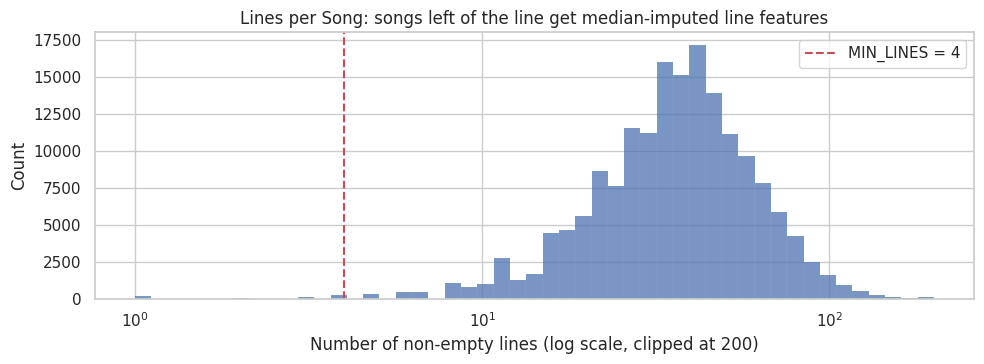

train 119,763 | val 25,668 | test 25,665
Share of songs with < 4 lines: train 0.17%, val 0.15%, test 0.17%


In [9]:
MIN_LINES = 4
LINE_FEATURES = ["line_count", "words_per_line", "line_repetition_rate", "top_line_share"]

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

line_medians = train_df.loc[train_df["line_count"] >= MIN_LINES, LINE_FEATURES].median()
few_line_share = {}
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    few = part["line_count"] < MIN_LINES
    few_line_share[name] = few.mean()
    part["few_lines"] = few.astype(int)
    part.loc[few, LINE_FEATURES] = line_medians.values

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.histplot(df["line_count"].clip(upper=200), bins=np.logspace(0, np.log10(200), 50), color="#4C72B0", ax=ax)
ax.set_xscale("log")
ax.axvline(MIN_LINES, color="#C44E52", ls="--", label=f"MIN_LINES = {MIN_LINES}")
ax.set_xlabel("Number of non-empty lines (log scale, clipped at 200)")
ax.set_title("Lines per Song: songs left of the line get median-imputed line features")
ax.legend()
savefig("L00c_line_count_check")

y_train = train_df["popularity"].values
y_val = val_df["popularity"].values
y_test = test_df["popularity"].values
print(f"train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,}")
print("Share of songs with < 4 lines: " + ", ".join(f"{k} {v:.2%}" for k, v in few_line_share.items()))

## 2.3 TF-IDF Parameters (Data-driven Choice)

TF-IDF weights each term in a song by its frequency in the song (TF) and its rarity across songs (IDF). sklearn computes $\text{idf}(t) = \ln\frac{1+n}{1+\text{df}(t)} + 1$, where n is the number of songs and df(t) the number of songs containing t. Terms that are frequent in a song but rare elsewhere receive the highest weights; each song vector is L2-normalized so that long and short songs are comparable.

### Preprocessing

Without preprocessing, the most common "keywords" were `i'm`, `know`, `don't`, and `it's`, because sklearn's English stop-word list contains no contractions. Ridge coefficients also treated `im` (negative) and `i'm`, or `cuz`/`cos` (negative) and `cause` (positive), as distinct terms. Spelling variants reflect **transcription quality**, not content.

| Step | Procedure | Rationale |
|---|---|---|
| Remove apostrophes | `i'm` → `im`, `don't` → `dont` | Merge spellings with and without apostrophes |
| Unify colloquial variants | `cuz`, `coz`, `cos` → `cause`; `yea` → `yeah` | Prevent the model from learning spelling habits |
| Add contractions to stop words | `im`, `dont`, `youre`, `cant`, … | Contractions are function words without content |

This preprocessing affects only TF-IDF (2.3–2.4), not the ten simple features in 2.1.

### Figures

Term statistics are computed on the **training set** with `CountVectorizer` without thresholds: the number of songs containing each term (document frequency) and its total count (term frequency).

| Panel | Question | Parameter | Interpretation |
|---|---|---|---|
| (a) Vocabulary size vs minimum document frequency | Should rare terms be removed, and at which threshold? | `min_df` | Raising the threshold from 1 to 2 removes more than half of the terms (mostly typos and names); the decline flattens beyond 5 |
| (b) Share of term occurrences covered by the top N terms | How many terms to keep? | `max_features` | Steep at first, then flat; the line marks 20,000 terms |
| (c) Share of songs containing the 25 most common terms | Should very common terms be removed? | `max_df` | The line marks 70%; contractions no longer appear |
| (d) Distinct terms per song | Sparsity of the matrix | (descriptive) | Each song uses only a few dozen of the 20,000 columns |

### Other parameters

| Parameter | Setting | Basis | Rationale |
|---|---|---|---|
| `stop_words` | English stop words + contractions | Research design | Function words carry no content |
| `sublinear_tf` | True | Research design | Choruses repeat words many times; 1 + log(count) prevents repeated words from dominating (repetition is captured by the simple features) |
| `token_pattern` | Alphabetic tokens of at least two letters | Research design | Removes single letters and numbers |

These statistics are computed on the training set only; using validation or test term frequencies would constitute leakage. The large count matrix is released after use to save memory.

Distinct words in train: 131,270 (33.2 s)


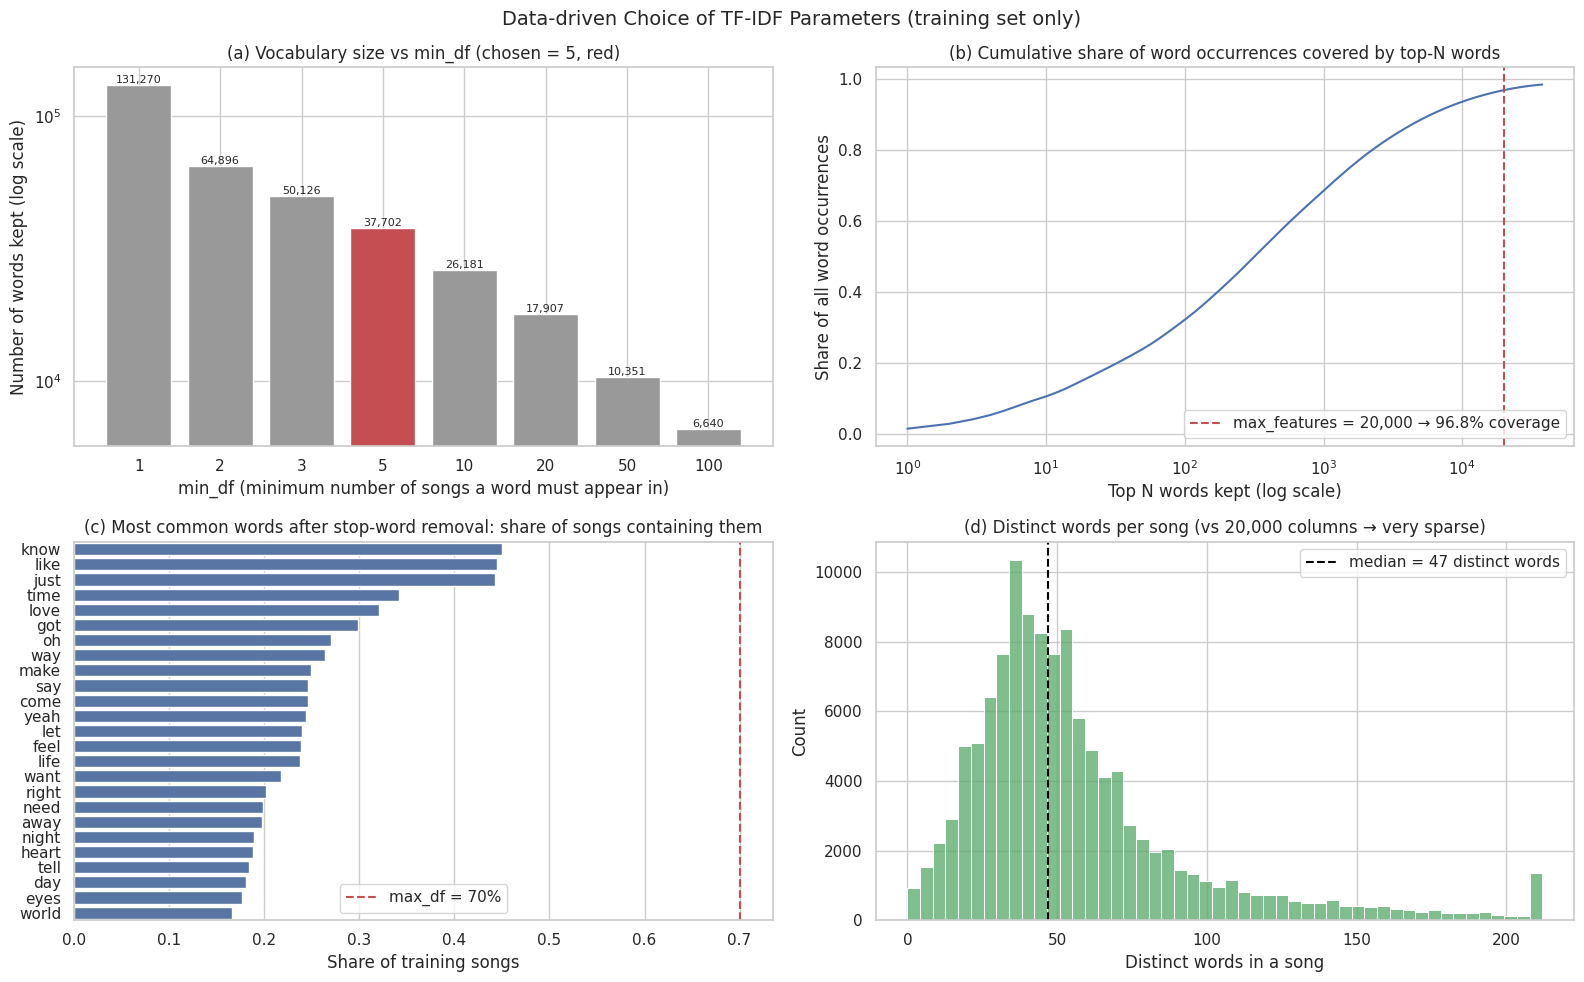

min_df=5: vocabulary reduced from 131,270 to 37,702
max_df=70%: 0 words above the threshold removed; the most common word appears in 45.0% of songs
max_features=20,000: covers 96.8% of word occurrences


In [10]:
APOS_RE = re.compile(r"[’'`]")
VARIANT_MAP = {"cuz": "cause", "coz": "cause", "cos": "cause", "yea": "yeah"}
VARIANT_RE = re.compile(r"\b(" + "|".join(VARIANT_MAP) + r")\b")

def lyrics_preprocessor(text):
    text = APOS_RE.sub("", text.lower())
    return VARIANT_RE.sub(lambda m: VARIANT_MAP[m.group(1)], text)

CONTRACTIONS = {
    "im", "ive", "ill", "id", "youre", "youve", "youll", "youd", "hes", "shes", "its", "were", "weve",
    "theyre", "theyve", "theyll", "theyd", "dont", "doesnt", "didnt", "cant", "couldnt", "wont",
    "wouldnt", "shouldnt", "isnt", "arent", "wasnt", "werent", "aint", "thats", "theres", "whats",
    "lets", "hasnt", "havent", "hadnt", "cause", "yall", "gonna", "wanna", "gotta",
}
STOP_WORDS = sorted(set(ENGLISH_STOP_WORDS) | CONTRACTIONS)
TOKEN_PATTERN = r"(?u)\b[a-z]{2,}\b"

t0 = time.time()
cv = CountVectorizer(preprocessor=lyrics_preprocessor, stop_words=STOP_WORDS,
                     token_pattern=TOKEN_PATTERN, dtype=np.int32)
C = cv.fit_transform(train_df["lyrics_model"])
all_words = np.array(cv.get_feature_names_out())
doc_freq = np.asarray((C > 0).sum(axis=0)).ravel()
term_freq = np.asarray(C.sum(axis=0)).ravel()
words_per_song = np.asarray((C > 0).sum(axis=1)).ravel()
n_docs = C.shape[0]
del C
print(f"Distinct words in train: {len(all_words):,} ({time.time() - t0:.1f} s)")

MIN_DF, MAX_DF, MAX_FEATURES = 5, 0.7, 20000
doc_share = doc_freq / n_docs
thresholds = [1, 2, 3, 5, 10, 20, 50, 100]
vocab_sizes = [int((doc_freq >= t).sum()) for t in thresholds]
eligible = (doc_freq >= MIN_DF) & (doc_share <= MAX_DF)
tf_sorted = np.sort(term_freq[eligible])[::-1]
coverage = np.cumsum(tf_sorted) / term_freq.sum()
cov_at_max = coverage[min(MAX_FEATURES, len(coverage)) - 1]
top25 = pd.DataFrame({"word": all_words, "doc_share": doc_share}).nlargest(25, "doc_share")
n_maxdf_removed = int((doc_share > MAX_DF).sum())

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
bar_colors = ["#C44E52" if t == MIN_DF else "#999999" for t in thresholds]
axes[0, 0].bar([str(t) for t in thresholds], vocab_sizes, color=bar_colors)
for i, v in enumerate(vocab_sizes):
    axes[0, 0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
axes[0, 0].set_yscale("log")
axes[0, 0].set_title(f"(a) Vocabulary size vs min_df (chosen = {MIN_DF}, red)")
axes[0, 0].set_xlabel("min_df (minimum number of songs a word must appear in)")
axes[0, 0].set_ylabel("Number of words kept (log scale)")

axes[0, 1].plot(np.arange(1, len(coverage) + 1), coverage, color="#4C72B0")
axes[0, 1].axvline(MAX_FEATURES, color="#C44E52", ls="--", label=f"max_features = {MAX_FEATURES:,} → {cov_at_max:.1%} coverage")
axes[0, 1].set_xscale("log")
axes[0, 1].set_title("(b) Cumulative share of word occurrences covered by top-N words")
axes[0, 1].set_xlabel("Top N words kept (log scale)")
axes[0, 1].set_ylabel("Share of all word occurrences")
axes[0, 1].legend(loc="lower right")

sns.barplot(data=top25, y="word", x="doc_share", color="#4C72B0", ax=axes[1, 0])
axes[1, 0].axvline(MAX_DF, color="#C44E52", ls="--", label=f"max_df = {MAX_DF:.0%}")
axes[1, 0].set_title("(c) Most common words after stop-word removal: share of songs containing them")
axes[1, 0].set_xlabel("Share of training songs")
axes[1, 0].set_ylabel("")
axes[1, 0].legend()

sns.histplot(np.clip(words_per_song, 0, np.percentile(words_per_song, 99)), bins=50, color="#55A868", ax=axes[1, 1])
axes[1, 1].axvline(np.median(words_per_song), color="black", ls="--", label=f"median = {np.median(words_per_song):.0f} distinct words")
axes[1, 1].set_title(f"(d) Distinct words per song (vs {MAX_FEATURES:,} columns → very sparse)")
axes[1, 1].set_xlabel("Distinct words in a song")
axes[1, 1].legend()
fig.suptitle("Data-driven Choice of TF-IDF Parameters (training set only)", fontsize=14)
savefig("L01_tfidf_parameter_choice")

print(f"min_df={MIN_DF}: vocabulary reduced from {vocab_sizes[0]:,} to {(doc_freq >= MIN_DF).sum():,}")
print(f"max_df={MAX_DF:.0%}: {n_maxdf_removed} words above the threshold removed; the most common word appears in {doc_share.max():.1%} of songs")
print(f"max_features={MAX_FEATURES:,}: covers {cov_at_max:.1%} of word occurrences")

## 2.4 TF-IDF Matrix (Fit on the Training Set Only)

Each song's lyrics are converted into a row of approximately 20,000 TF-IDF values using the parameters from 2.3.

**The TF-IDF vectorizer is fit on the training set only and then applied to the validation and test sets.**

```
Correct:   split → fit TF-IDF on train → transform val / test with the same vectorizer
Incorrect: fit TF-IDF on all data → split
```

Fitting determines the vocabulary and the IDF weights. Fitting on all data would expose the vectorizer to the vocabulary and term frequencies of the test set; although popularity is not observed, the test distribution would enter preprocessing, which constitutes **data leakage**. *All text preprocessing was fitted only on the training set to avoid leakage.*

Each song uses only a small fraction of the vocabulary, so the matrix is stored in sparse format, which records only non-zero entries. The output reports the matrix dimensions and its sparsity (expected above 99%).

In [11]:
tfidf = TfidfVectorizer(
    preprocessor=lyrics_preprocessor,
    max_features=MAX_FEATURES,
    min_df=MIN_DF,
    max_df=MAX_DF,
    stop_words=STOP_WORDS,
    sublinear_tf=True,
    token_pattern=TOKEN_PATTERN,
    dtype=np.float32,
)

t0 = time.time()
Xt_tr = tfidf.fit_transform(train_df["lyrics_model"])
Xt_va = tfidf.transform(val_df["lyrics_model"])
Xt_te = tfidf.transform(test_df["lyrics_model"])
vocab = np.array(tfidf.get_feature_names_out())
sparsity = 1 - Xt_tr.nnz / np.prod(Xt_tr.shape)
print(f"TF-IDF completed ({time.time() - t0:.1f} s)")
print(f"Training matrix: {Xt_tr.shape[0]:,} songs × {Xt_tr.shape[1]:,} terms, sparsity {sparsity:.4%}")
print("Check: contractions and tags removed?", [w for w in ["im", "dont", "its", "chorus", "instrumental"] if w in set(vocab)] or "all removed")

TF-IDF completed (45.6 s)
Training matrix: 119,763 songs × 20,000 terms, sparsity 99.7286%
Check: contractions and tags removed? ['chorus', 'instrumental']


---
# Part 3 — Lyrics Features and Popularity (SQ2)

Before modeling, the association between the ten lyrics features and popularity is described with statistics and figures. All analyses use the training set only.

| Section | Question | Method | Figure |
|---|---|---|---|
| 3.1 | Distributions of popularity and the lyrics features | Histograms | L02 |
| 3.2 | Overlap among features | Inter-correlation heat map | L03 |
| 3.3 | Strength of each feature's association with popularity | Spearman correlation | L04 (Figure 3, left) |
| 3.4 | Differences between hit songs and other songs | Cohen's d and tiered box plots | L05 (Figure 3, right), L06 |

## 3.1 Distributions

The distributions of popularity and the ten lyrics features are shown to verify plausible ranges, to characterize typical songs, and to assess the **skewness** of popularity. A right-skewed target (most songs with low scores and a long tail of high scores) typically leads models to under-predict popular songs, which is relevant for the baseline comparison in 4.1. Skewness near 0 indicates symmetry; positive values indicate a right tail.

Values are clipped at the 1st and 99th percentiles for display only; the data are not altered. Colors denote the feature dimensions throughout the notebook: blue = length, orange = repetition, green = sentiment.

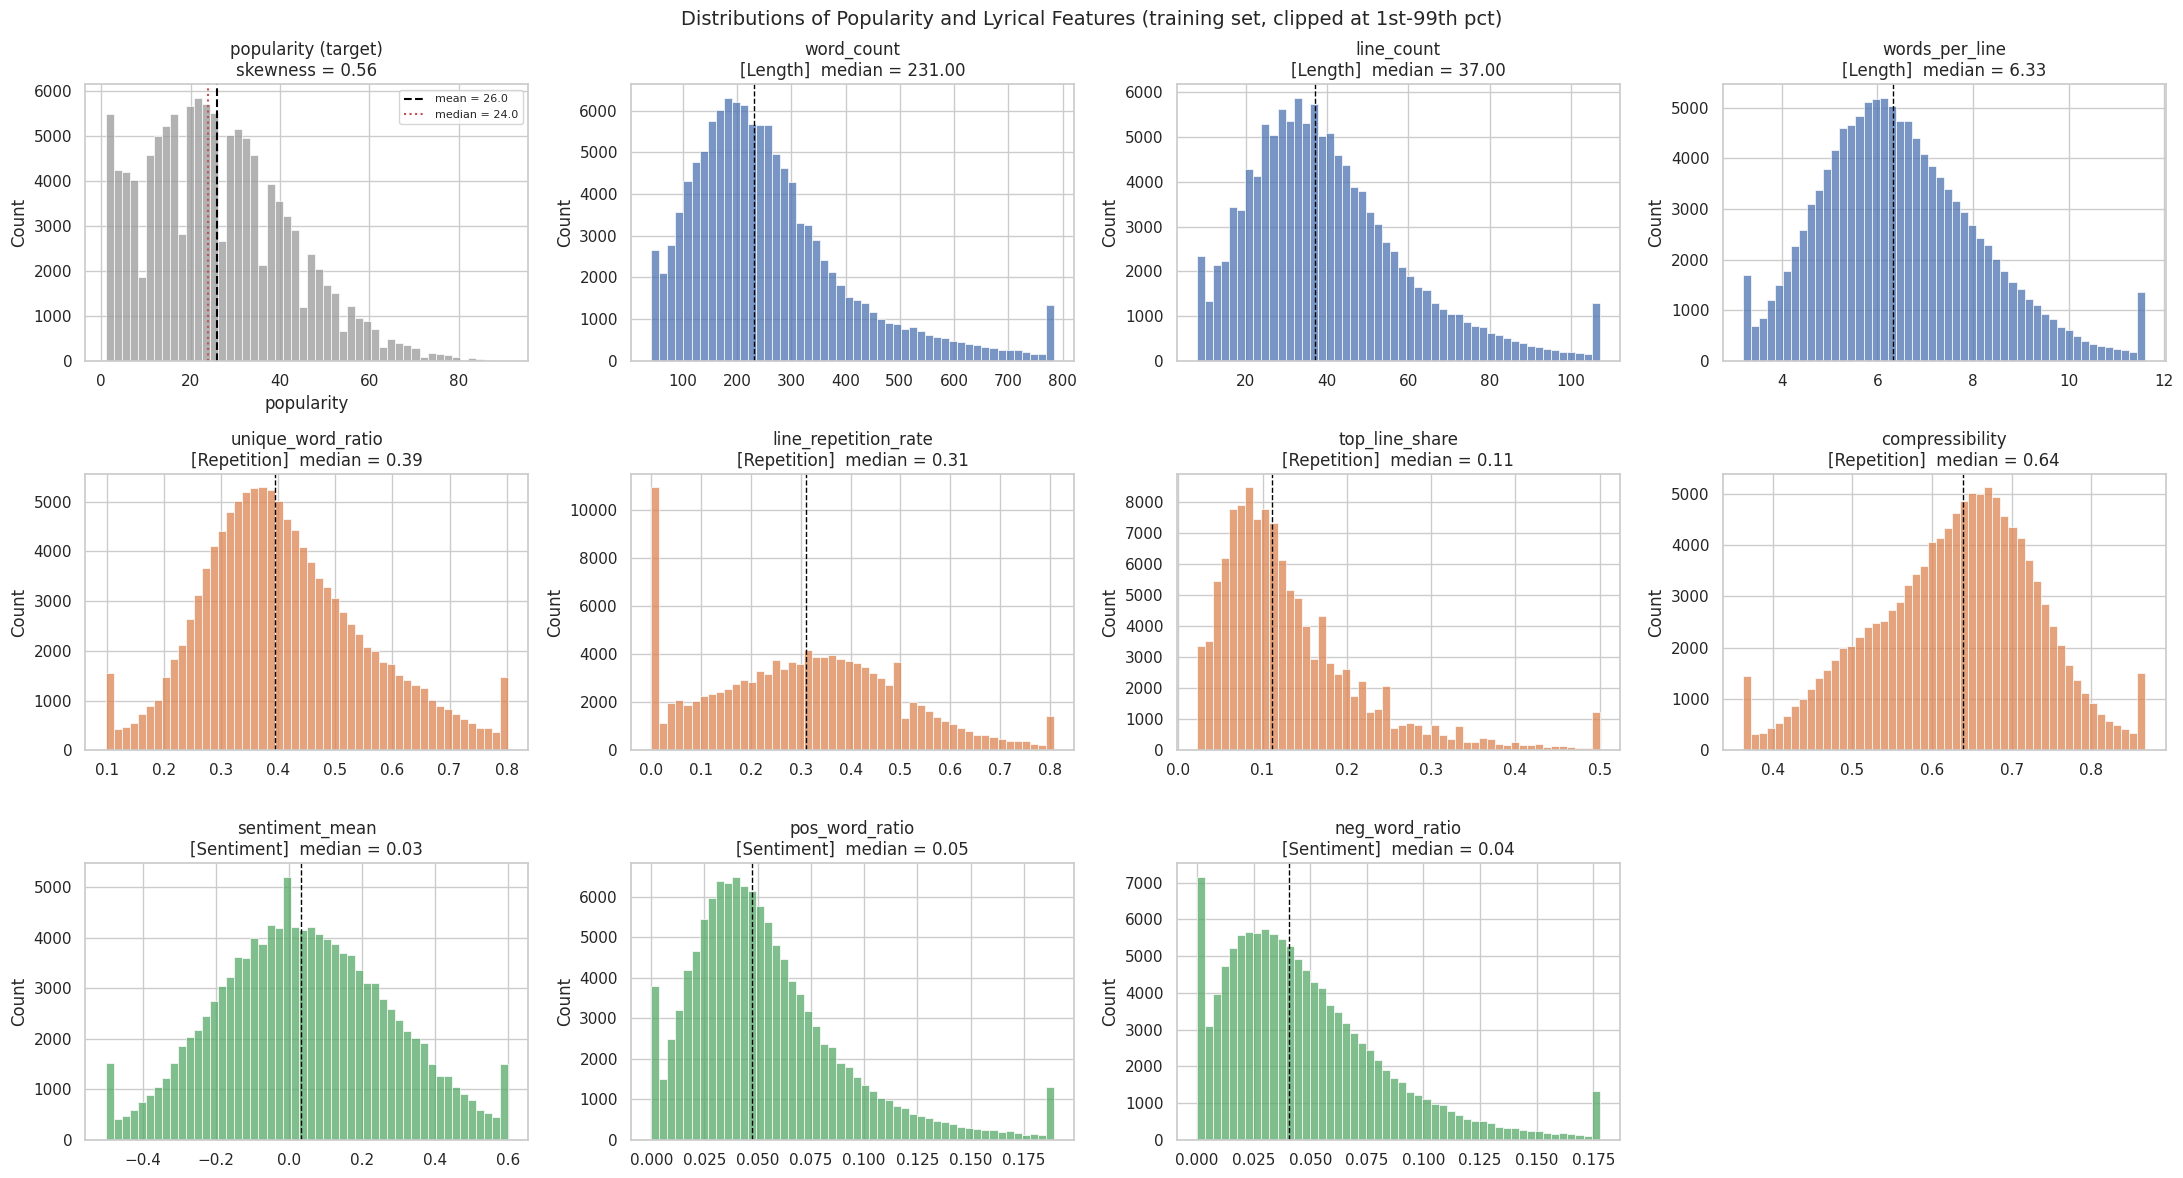

Popularity (train): mean = 25.98, median = 24.00, std = 15.97, skewness = 0.56


In [12]:
pop = train_df["popularity"]
fig, axes = plt.subplots(3, 4, figsize=(22, 12))
sns.histplot(pop, bins=50, color="#999999", ax=axes[0, 0])
axes[0, 0].axvline(pop.mean(), color="black", ls="--", label=f"mean = {pop.mean():.1f}")
axes[0, 0].axvline(pop.median(), color="#C44E52", ls=":", label=f"median = {pop.median():.1f}")
axes[0, 0].set_title(f"popularity (target)\nskewness = {pop.skew():.2f}")
axes[0, 0].legend(fontsize=8)
for f, ax in zip(LYRIC_FEATURES, axes.ravel()[1:]):
    lo, hi = train_df[f].quantile([0.01, 0.99])
    sns.histplot(train_df[f].clip(lo, hi), bins=50, ax=ax, color=GROUP_COLORS[FEATURE_TO_GROUP[f]])
    ax.axvline(train_df[f].median(), color="black", ls="--", lw=1)
    ax.set_title(f"{f}\n[{FEATURE_TO_GROUP[f]}]  median = {train_df[f].median():.2f}")
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
fig.suptitle("Distributions of Popularity and Lyrical Features (training set, clipped at 1st-99th pct)", fontsize=14)
savefig("L02_distributions")
print(f"Popularity (train): mean = {pop.mean():.2f}, median = {pop.median():.2f}, std = {pop.std():.2f}, skewness = {pop.skew():.2f}")

## 3.2 Feature Inter-correlation

The heat map shows pairwise Spearman correlations among the ten lyrics features.

Highly correlated features (e.g., `word_count` and `line_count`) carry largely overlapping information. Under such **multicollinearity**, coefficients in a linear model compete for shared variance; individual signs may be unstable and may even reverse relative to the bivariate association. Coefficients of highly correlated features are therefore interpreted jointly, which is one reason for using Ridge rather than OLS.

Red indicates positive and blue negative correlation; |ρ| ≥ 0.7 is treated as high (a common convention). Correlations are computed on a sample of 50,000 training songs; with a standard error of about 1/√n ≈ 0.005, the estimates are highly stable.

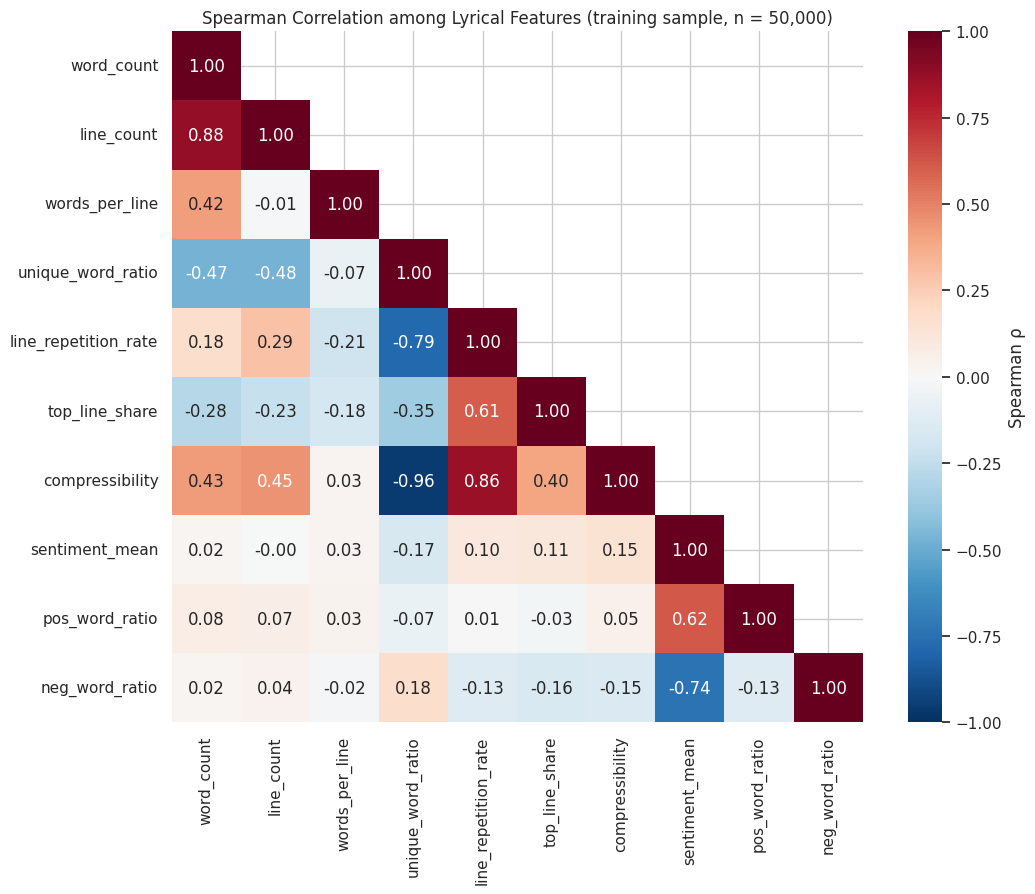

Highly correlated feature pairs (|ρ| ≥ 0.7); their coefficients should be interpreted jointly:
           feature_1            feature_2     rho
   unique_word_ratio      compressibility -0.9575
          word_count           line_count  0.8771
line_repetition_rate      compressibility  0.8595
   unique_word_ratio line_repetition_rate -0.7874
      sentiment_mean       neg_word_ratio -0.7387


In [13]:
sample = train_df[LYRIC_FEATURES].sample(n=min(50000, len(train_df)), random_state=RANDOM_STATE)
inter_corr = sample.corr(method="spearman")

plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(inter_corr, dtype=bool), k=1)
sns.heatmap(inter_corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, cbar_kws={"label": "Spearman ρ"})
plt.title(f"Spearman Correlation among Lyrical Features (training sample, n = {len(sample):,})")
savefig("L03_feature_intercorrelation")

pairs = inter_corr.where(np.triu(np.ones(inter_corr.shape, dtype=bool), k=1)).stack().reset_index()
pairs.columns = ["feature_1", "feature_2", "rho"]
high_pairs = pairs[pairs["rho"].abs() >= 0.7].sort_values("rho", key=abs, ascending=False)
print("Highly correlated feature pairs (|ρ| ≥ 0.7); their coefficients should be interpreted jointly:")
print(high_pairs.to_string(index=False) if len(high_pairs) else "(none)")

## 3.3 Spearman Correlation with Popularity

The association between each lyrics feature and popularity is measured by Spearman's ρ and grouped by dimension.

| | Pearson | **Spearman** |
|---|---|---|
| Relationship measured | Linear only | **Monotonic** (not necessarily linear) |
| Sensitivity to extreme values | High | Low (values replaced by ranks) |
| Suitable for | Approximately normal data | Skewed data (word counts and popularity are skewed) |

| \|ρ\| | Strength |
|---|---|
| < 0.1 | Very weak |
| 0.1–0.3 | Weak |
| 0.3–0.5 | Moderate |
| > 0.5 | Strong |

The gray band marks |ρ| < 0.1. With about 120,000 training songs, almost every correlation is statistically significant, so the **magnitude** of ρ rather than the p-value is interpreted. The output identifies, for each dimension, the feature with the largest |ρ| and its direction.

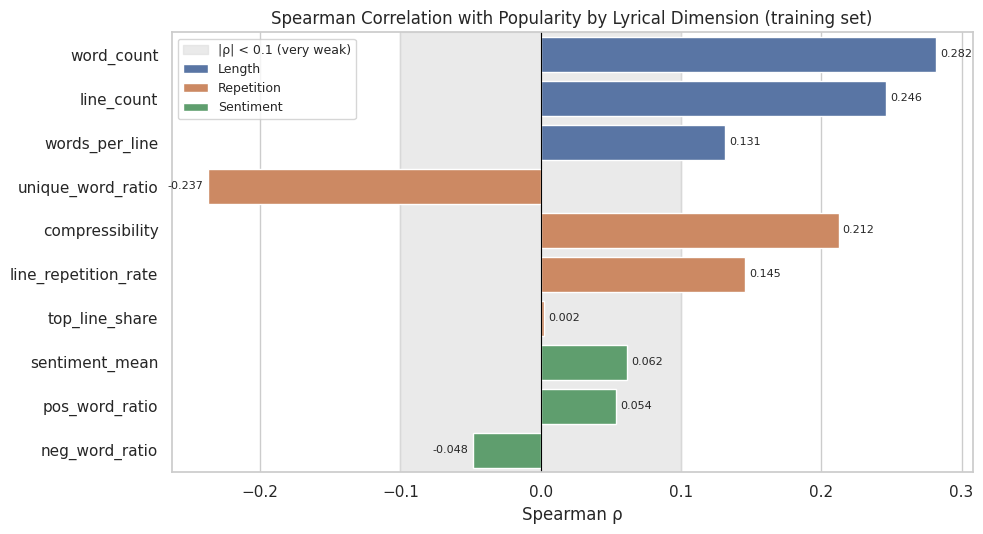

,group,feature,spearman_rho,abs_rho,p_value,strength
0,Length,word_count,0.2820,0.2820,0.0000,weak
1,Length,line_count,0.2463,0.2463,0.0000,weak
2,Length,words_per_line,0.1313,0.1313,0.0000,weak
3,Repetition,unique_word_ratio,-0.2371,0.2371,0.0000,weak
4,Repetition,compressibility,0.2123,0.2123,0.0000,weak
5,Repetition,line_repetition_rate,0.1454,0.1454,0.0000,weak
6,Repetition,top_line_share,0.0021,0.0021,0.4662,very weak
7,Sentiment,sentiment_mean,0.0615,0.0615,0.0000,very weak
8,Sentiment,pos_word_ratio,0.0536,0.0536,0.0000,very weak
9,Sentiment,neg_word_ratio,-0.0484,0.0484,0.0000,very weak


In [14]:
rows = []
for f in LYRIC_FEATURES:
    rho, p = spearmanr(train_df[f], train_df["popularity"])
    rows.append({"group": FEATURE_TO_GROUP[f], "feature": f, "spearman_rho": rho, "abs_rho": abs(rho), "p_value": p})
corr_df = pd.DataFrame(rows).sort_values(["group", "abs_rho"], ascending=[True, False]).reset_index(drop=True)

def strength(r):
    a = abs(r)
    return "very weak" if a < 0.1 else "weak" if a < 0.3 else "moderate" if a < 0.5 else "strong"
corr_df["strength"] = corr_df["spearman_rho"].map(strength)

plt.figure(figsize=(10, 5.5))
plt.axvspan(-0.1, 0.1, color="#DDDDDD", alpha=0.6, label="|ρ| < 0.1 (very weak)")
sns.barplot(data=corr_df, y="feature", x="spearman_rho", hue="group", palette=GROUP_COLORS, dodge=False)
for i, r in enumerate(corr_df["spearman_rho"]):
    plt.text(r + (0.003 if r >= 0 else -0.003), i, f"{r:.3f}", va="center", ha="left" if r >= 0 else "right", fontsize=8)
plt.axvline(0, color="black", lw=0.8)
plt.title("Spearman Correlation with Popularity by Lyrical Dimension (training set)")
plt.xlabel("Spearman ρ")
plt.ylabel("")
plt.legend(loc="best", fontsize=9)
savefig("L04_spearman_by_dimension")
corr_df